# Secure Aggregation — testes isolados com ponderação pelo fit

Dados reais do treino validado: candidata A, seed 2031, três rondas, 22 clientes, 32 âncoras e duas classes. Origem: `SoftLabels tests/final candidates/sa_inputs/fit_weighted_v2/manifest.json`.

Cada cliente tem 128 exemplos de fit e peso 1/22: **Icentia 16/22 (72,73%) e PhysioNet 6/22 (27,27%)**. Tanto `weighted` como `per_origin` usam os pesos dos ficheiros. `weighted` revela uma soma única; `per_origin` revela somas separadas por origem, que são depois adicionadas. Não se aplica 50/50.

Com desistências, os pesos são renormalizados entre quem enviou a mensagem mascarada. SA e referência sem SA usam exatamente os mesmos sobreviventes. Quem envia a mensagem mas desiste no desmascaramento continua incluído, se o limiar permitir recuperar a soma.

São testes isolados de precisão numérica, robustez e custo local; não voltam a treinar modelos nem medem PR-AUC. Tempos não incluem rede real. Os resultados anteriores estão em `artifacts/sa_support/history/before_fit_weighted_sa/`.


In [1]:
import numpy as np
import pandas as pd
import protocol as sa

## 1. Verificação do protocolo

In [2]:
def check(nome, ok):
    assert ok, nome
    print(('OK    ' if ok else 'FALHA ') + nome)

# troca de chaves: valores de teste do RFC 7748 (secção 6.1)
alice = bytes.fromhex('77076d0a7318a57d3c16c17251b26645df4c2f87ebc0992ab177fba51db92c2a')
bob   = bytes.fromhex('5dab087e624a8a4b79e17f8b83800ee66f3bb1292618b6fd1c2f8b27ff88e0eb')
A, B = sa.x25519(alice, sa.BASE), sa.x25519(bob, sa.BASE)
check('X25519: chave pública da Alice', A.hex() == '8520f0098930a754748b7ddcb43ef75a0dbf3a0d26381af4eba4a98eaa9b4e6a')
check('X25519: segredo partilhado', sa.x25519(alice, B) == sa.x25519(bob, A) ==
      bytes.fromhex('4a5d9d5ba4ce2de1728e3bf480350f25e07e21c947d19e3376f09b3c1e161742'))

# Shamir: t pedaços recuperam o segredo, t-1 não
p = sa.share(12345, 3, [1, 2, 3, 4, 5])
check('Shamir: 3 pedaços recuperam o segredo', sa.reconstruct({k: p[k] for k in [1, 3, 5]}) == 12345)
check('Shamir: 2 pedaços não recuperam', sa.reconstruct({k: p[k] for k in [1, 3]}) != 12345)

# cifragem: decifra e deteta alterações
key = bytes(32); box = sa.seal(key, b'pedaco')
check('Cifragem: decifra', sa.unseal(key, box) == b'pedaco')
try:
    sa.unseal(key, box[:-1] + bytes([box[-1] ^ 1])); check('Cifragem: deteta alteração', False)
except ValueError:
    check('Cifragem: deteta alteração', True)

# soma segura: exata, com e sem desistências; recusa abaixo de t
rng = np.random.default_rng(0)
X = {u: rng.integers(0, 2**20, 64).astype(np.uint64) for u in range(1, 11)}
for dm, du in [((), ()), ((2, 7), ()), ((2, 7), (1,))]:
    tot, rep = sa.secure_sum(X, t=6, drop_masked=dm, drop_unmask=du)
    check(f'Soma exata (desistem antes de enviar {dm}, antes de desmascarar {du})',
          np.array_equal(tot, sum(X[u] for u in rep['survivor_ids']) % sa.MOD))
try:
    sa.secure_sum(X, t=9, drop_masked=(1, 2)); check('Recusa com menos de t clientes', False)
except RuntimeError:
    check('Recusa com menos de t clientes', True)

OK    X25519: chave pública da Alice
OK    X25519: segredo partilhado
OK    Shamir: 3 pedaços recuperam o segredo
OK    Shamir: 2 pedaços não recuperam
OK    Cifragem: decifra
OK    Cifragem: deteta alteração


OK    Soma exata (desistem antes de enviar (), antes de desmascarar ())


OK    Soma exata (desistem antes de enviar (2, 7), antes de desmascarar ())


OK    Soma exata (desistem antes de enviar (2, 7), antes de desmascarar (1,))


OK    Recusa com menos de t clientes


## 2. O que o servidor vê

In [3]:
exemplo = {u: np.array([10*u, 1, 2], dtype=np.uint64) for u in range(1, 6)}
total, rep = sa.secure_sum(exemplo, t=3)
pd.DataFrame({'valor real': {u: v.tolist() for u, v in exemplo.items()},
              'recebido pelo servidor': {u: v.tolist() for u, v in rep['server_view'].items()}})

,valor real,recebido pelo servidor
1,"[10, 1, 2]","[634940589, 1149956371, 1165107948]"
2,"[20, 1, 2]","[3604273806, 2912412918, 4091800435]"
3,"[30, 1, 2]","[2662733030, 255665899, 815783917]"
4,"[40, 1, 2]","[2269474925, 3762667657, 656890907]"
5,"[50, 1, 2]","[3480839448, 2575123305, 1302525046]"


In [4]:
print('soma pela SA:', total.tolist(), '| soma verdadeira:', sum(exemplo.values()).tolist())

soma pela SA: [150, 5, 10] | soma verdadeira: [150, 5, 10]


## 3. Dados

In [5]:
rounds = sa.load_rounds()
ids = rounds[0]['client_ids']
print(rounds[0]['logits'].shape, pd.Series([sa.origin(c) for c in ids]).value_counts().to_dict())
for r in rounds:
    erro = np.abs(sa.plain_consensus(sa.softmax(r['logits']), r['client_ids'], planned_weights=r['weights']) - r['consensus']).max()
    print(f"ronda {r['round']}: referência sem SA vs consenso guardado = {erro:.1e}")
for ds in sorted({sa.origin(c) for c in ids}):
    mask=np.array([sa.origin(c)==ds for c in ids])
    print(f"{ds}: {mask.sum()} clientes; peso {rounds[0]['weights'][mask].sum():.6%}")
for r in rounds:
    assert np.allclose(sa.plain_consensus(sa.softmax(r['logits']),r['client_ids'],planned_weights=r['weights']),r['consensus'],atol=1e-7)


(22, 32, 2) {'icentia11k': 16, 'physionet2017': 6}
ronda 1: referência sem SA vs consenso guardado = 3.2e-08
ronda 2: referência sem SA vs consenso guardado = 4.1e-08
ronda 3: referência sem SA vs consenso guardado = 2.9e-08
icentia11k: 16 clientes; peso 72.727273%
physionet2017: 6 clientes; peso 27.272727%


## 4. Sanidade: SA vs consenso original (t = 12, 16 bits)

In [6]:
rows = []
for r in rounds:
    probs = sa.softmax(r['logits'])
    for mode in ('per_origin', 'weighted'):
        c, rep, _ = sa.sa_consensus(probs, r['client_ids'], t=12, bits=16, mode=mode, planned_weights=r['weights'])
        rows.append(dict(ronda=r['round'], modo=mode, **sa.compare(c, r['consensus']),
                         tempo_s=round(rep['wall_seconds'], 2),
                         upload_kb=rep['upload_bytes_mean']/1024, upload_kb_sem_sa=rep['plain_upload_bytes']/1024))
pd.DataFrame(rows)

,ronda,modo,erro_max,mae,decisoes_alteradas,tempo_s,upload_kb,upload_kb_sem_sa
0,1,per_origin,0.000042,0.000014,0,1.97,5.425781,0.50
1,1,weighted,0.000042,0.000014,0,1.96,5.175781,0.25
2,2,per_origin,0.000034,0.000013,0,1.94,5.425781,0.50
3,2,weighted,0.000034,0.000013,0,1.96,5.175781,0.25
4,3,per_origin,0.000045,0.000014,0,1.97,5.425781,0.50
5,3,weighted,0.000045,0.000014,0,1.97,5.175781,0.25


## 5. Com 4 desistências (referência: sem SA, só com quem ficou)

In [7]:
r = rounds[0]; probs = sa.softmax(r['logits'])
drop = (1, 2, 17, 18)   # uids 1-16 Icentia, 17-22 PhysioNet
rows = []
for mode in ('per_origin', 'weighted'):
    c, rep, surv = sa.sa_consensus(probs, r['client_ids'], t=12, bits=16, mode=mode,
                                   drop_masked=drop, planned_weights=r['weights'])
    rows.append(dict(modo=mode, sobreviventes=rep['survivors'],
                     **sa.compare(c, sa.plain_consensus(probs, r['client_ids'], surv, planned_weights=r['weights']))))
pd.DataFrame(rows)

,modo,sobreviventes,erro_max,mae,decisoes_alteradas
0,per_origin,18,0.000046,0.000014,0
1,weighted,18,0.000046,0.000014,0


## 6. Experiências

In [8]:
import math
from pathlib import Path
import matplotlib.pyplot as plt

OUT = Path('results'); OUT.mkdir(exist_ok=True)
N = len(ids)
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': .6,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'font.size': 10,
                     'lines.linewidth': 2, 'lines.markersize': 6})

def save(fig, name):
    fig.tight_layout(); fig.savefig(OUT/f'{name}.png', dpi=200, bbox_inches='tight')

def p_success(n, t, d):
    # probabilidade de ficarem pelo menos t clientes quando cada um desiste com prob. d
    return sum(math.comb(n, k)*(1-d)**k*d**(n-k) for k in range(t, n+1))

Matplotlib is building the font cache; this may take a moment.


### 6.1 Erro de quantização vs bits

In [9]:
BITS = [4, 6, 8, 10, 12, 14, 16, 20, 24, 27]
rows = []
for r in rounds:
    probs = sa.softmax(r['logits'])
    for mode in ('per_origin', 'weighted'):
        for b in BITS:
            c, rep, _ = sa.sa_consensus(probs, ids, t=12, bits=b, mode=mode, planned_weights=r['weights'])
            rows.append(dict(ronda=r['round'], modo=mode, bits=b, **sa.compare(c, r['consensus'])))
e_bits = pd.DataFrame(rows); e_bits.to_csv(OUT/'e1_bits.csv', index=False)
tab_bits = e_bits.groupby(['modo', 'bits']).agg(mae=('mae', 'mean'), erro_max=('erro_max', 'max'),
                                                decisoes_alteradas=('decisoes_alteradas', 'sum')).reset_index()
tab_bits.pivot(index='bits', columns='modo', values=['mae', 'erro_max', 'decisoes_alteradas'])

mae                    erro_max                \
modo    per_origin      weighted    per_origin      weighted   
bits                                                           
4     1.517251e-01  1.517251e-01  3.480615e-01  3.480615e-01   
6     1.633340e-02  1.633340e-02  5.646563e-02  5.646563e-02   
8     1.116374e-02  1.116374e-02  2.719301e-02  2.719301e-02   
10    3.164126e-03  3.164126e-03  8.237362e-03  8.237362e-03   
12    3.610952e-04  3.610952e-04  9.360313e-04  9.360313e-04   
14    1.241209e-04  1.241209e-04  3.538132e-04  3.538132e-04   
16    1.361729e-05  1.361729e-05  4.458427e-05  4.458427e-05   
20    2.233040e-06  2.233040e-06  7.152557e-06  7.152557e-06   
24    1.014754e-07  1.014754e-07  2.980232e-07  2.980232e-07   
27    1.350418e-08  1.350418e-08  5.960464e-08  5.960464e-08   

     decisoes_alteradas           
modo         per_origin weighted  
bits                              
4                   0.0      0.0  
6                   0.0      0.0  
8                   0.0      0.0  
10                  0.0      0.0  
12                  0.0      0.0  
14                  0.0      0.0  
16                  0.0      0.0  
20                  0.0      0.0  
24                  0.0      0.0  
27                  0.0      0.0

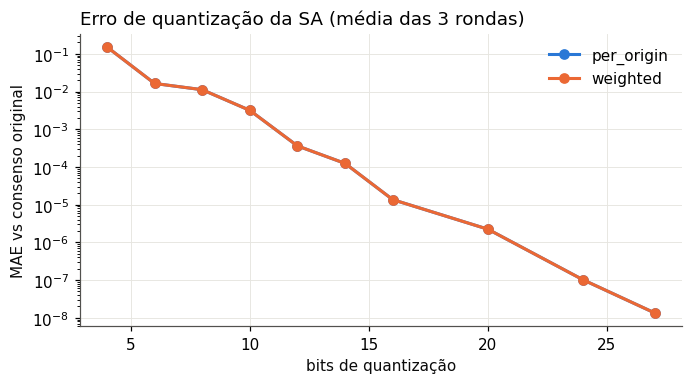

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for color, (mode, g) in zip(COLORS, tab_bits.groupby('modo')):
    ax.plot(g['bits'], g['mae'], marker='o', color=color, label=mode)
ax.set_yscale('log'); ax.set_xlabel('bits de quantização'); ax.set_ylabel('MAE vs consenso original')
ax.set_title('Erro de quantização da SA (média das 3 rondas)', loc='left')
ax.legend(frameon=False); save(fig, 'e1_bits')

### 6.2 Limiar: ronda com t − 1, t e t + 1 clientes (t = 12)

In [11]:
r = rounds[0]; probs = sa.softmax(r['logits']); rows = []
for survivors in (10, 11, 12, 13, 14):
    drop = tuple(range(1, N-survivors+1))
    try:
        c, rep, surv = sa.sa_consensus(probs, ids, t=12, bits=16, drop_masked=drop, planned_weights=r['weights'])
        rows.append(dict(sobreviventes=survivors, ronda_concluida=True, **sa.compare(c, sa.plain_consensus(probs, ids, surv, planned_weights=r['weights']))))
    except RuntimeError as e:
        rows.append(dict(sobreviventes=survivors, ronda_concluida=False, motivo=str(e)))
# desistências durante o desmascaramento: 18 enviam dados, k não respondem na etapa 3
for k in (0, 4, 6, 7):
    drop2 = tuple(range(1, 5)); drop3 = tuple(range(5, 5+k))
    try:
        c, rep, surv = sa.sa_consensus(probs, ids, t=12, bits=16, drop_masked=drop2, drop_unmask=drop3, planned_weights=r['weights'])
        rows.append(dict(sobreviventes=18, respondem_etapa3=18-k, ronda_concluida=True,
                         **sa.compare(c, sa.plain_consensus(probs, ids, surv, planned_weights=r['weights']))))
    except RuntimeError as e:
        rows.append(dict(sobreviventes=18, respondem_etapa3=18-k, ronda_concluida=False, motivo=str(e)))
e_limiar = pd.DataFrame(rows); e_limiar.to_csv(OUT/'e2_limiar.csv', index=False); e_limiar

,sobreviventes,ronda_concluida,motivo,erro_max,mae,decisoes_alteradas,respondem_etapa3
0,10,False,"Only 10 masked inputs, t=12",NaN,NaN,NaN,NaN
1,11,False,"Only 11 masked inputs, t=12",NaN,NaN,NaN,NaN
2,12,True,NaN,0.000058,0.000023,0.0,NaN
3,13,True,NaN,0.000052,0.000022,0.0,NaN
4,14,True,NaN,0.000048,0.000020,0.0,NaN
5,18,True,NaN,0.000042,0.000016,0.0,18.0
6,18,True,NaN,0.000042,0.000016,0.0,14.0
7,18,True,NaN,0.000042,0.000016,0.0,12.0
8,18,False,"Only 11 responses, t=12",NaN,NaN,NaN,11.0


### 6.3 Desistências × limiar t (weighted, 16 bits, 10 repetições por célula)

In [12]:
T = [6, 8, 12, 15, 18]; D = [0, .1, .2, .3, .4, .5]; REPS = 10
rng = np.random.default_rng(2026); rows = []
for t in T:
    for d in D:
        for k in range(REPS):
            r = rounds[k % 3]; probs = sa.softmax(r['logits'])
            drop = tuple(u for u in range(1, N+1) if rng.random() < d)
            row = dict(t=t, desistencia=d, rep=k, desistiram=len(drop))
            try:
                c, rep, surv = sa.sa_consensus(probs, ids, t=t, bits=16, drop_masked=drop, planned_weights=r['weights'])
                row.update(ronda_concluida=True, tempo_s=rep['wall_seconds'], upload_bytes=rep['upload_bytes_mean'],
                           **sa.compare(c, sa.plain_consensus(probs, ids, surv, planned_weights=r['weights'])))
            except RuntimeError:
                row.update(ronda_concluida=False)
            rows.append(row)
e_drop = pd.DataFrame(rows); e_drop.to_csv(OUT/'e3_desistencias.csv', index=False)
tab_drop = e_drop.groupby(['t', 'desistencia']).agg(sucesso=('ronda_concluida', 'mean'), mae=('mae', 'mean'),
                                                    tempo_s=('tempo_s', 'mean')).reset_index()
tab_drop['sucesso_teorico'] = [p_success(N, t, d) for t, d in zip(tab_drop['t'], tab_drop['desistencia'])]
tab_drop.pivot(index='desistencia', columns='t', values='sucesso')

t,6,8,12,15,18
desistencia,,,,,
0.0,1.0,1.0,1.0,1.0,1.0
0.1,1.0,1.0,1.0,1.0,1.0
0.2,1.0,1.0,1.0,0.9,0.4
0.3,1.0,1.0,0.9,0.5,0.3
0.4,1.0,1.0,1.0,0.5,0.0
0.5,1.0,0.9,0.4,0.1,0.0


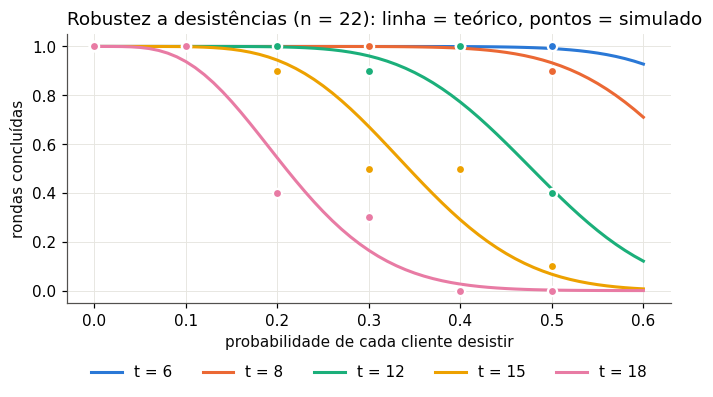

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.8)); dd = np.linspace(0, .6, 61)
for color, t in zip(COLORS, T):
    g = tab_drop[tab_drop['t'] == t]
    ax.plot(dd, [p_success(N, t, d) for d in dd], color=color, label=f't = {t}')
    ax.plot(g['desistencia'], g['sucesso'], 'o', color=color, markeredgecolor='white', markeredgewidth=1.5)
ax.set_xlabel('probabilidade de cada cliente desistir'); ax.set_ylabel('rondas concluídas')
ax.set_title('Robustez a desistências (n = 22): linha = teórico, pontos = simulado', loc='left')
ax.legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(.5, -.18)); save(fig, 'e3_desistencias')

In [14]:
# compromisso do limiar: limiar Shamir menos um (não uma garantia isolada de conluio) vs desistências toleradas (n - t)
seg = pd.DataFrame(dict(t=T, limiar_shamir_menos_1=[t-1 for t in T], desistencias_toleradas=[N-t for t in T],
                        sucesso_20pct=[p_success(N, t, .2) for t in T], sucesso_30pct=[p_success(N, t, .3) for t in T]))
seg.to_csv(OUT/'e3_limiar_compromisso.csv', index=False); seg

,t,limiar_shamir_menos_1,desistencias_toleradas,sucesso_20pct,sucesso_30pct
0,6,5,16,1.000000,0.999994
1,8,7,14,0.999999,0.999754
2,12,11,10,0.998410,0.961255
3,15,14,7,0.943855,0.671251
4,18,17,4,0.542882,0.164549


### 6.4 Soma por origem vs soma única — ambas ponderadas pelo fit (t = 8)

In [15]:
rng = np.random.default_rng(7); rows = []
for d in (0, .1, .2, .3, .4):
    for k in range(5):
        r = rounds[k % 3]; probs = sa.softmax(r['logits'])
        drop = tuple(u for u in range(1, N+1) if rng.random() < d)
        for mode in ('per_origin', 'weighted'):
            c, rep, surv = sa.sa_consensus(probs, ids, t=8, bits=16, mode=mode, drop_masked=drop, planned_weights=r['weights'])
            rows.append(dict(desistencia=d, rep=k, modo=mode, **sa.compare(c, sa.plain_consensus(probs, ids, surv, planned_weights=r['weights']))))
e_modo = pd.DataFrame(rows); e_modo.to_csv(OUT/'e4_modo.csv', index=False)
tab_modo = e_modo.groupby(['modo', 'desistencia']).agg(mae=('mae', 'mean'), erro_max=('erro_max', 'max'),
                                                       decisoes_alteradas=('decisoes_alteradas', 'sum')).reset_index()
tab_modo.pivot(index='desistencia', columns='modo', values=['mae', 'decisoes_alteradas'])

mae           decisoes_alteradas         
modo        per_origin  weighted         per_origin weighted
desistencia                                                 
0.0           0.000014  0.000014                0.0      0.0
0.1           0.000014  0.000014                0.0      0.0
0.2           0.000015  0.000015                0.0      0.0
0.3           0.000016  0.000016                0.0      0.0
0.4           0.000016  0.000016                0.0      0.0

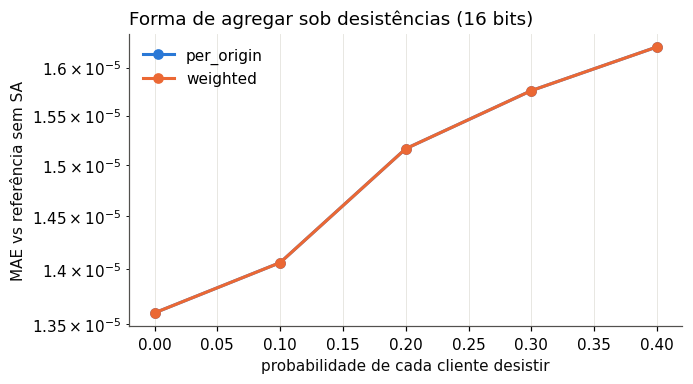

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for color, (mode, g) in zip(COLORS, tab_modo.groupby('modo')):
    ax.plot(g['desistencia'], g['mae'], marker='o', color=color, label=mode)
ax.set_yscale('log'); ax.set_xlabel('probabilidade de cada cliente desistir'); ax.set_ylabel('MAE vs referência sem SA')
ax.set_title('Forma de agregar sob desistências (16 bits)', loc='left'); ax.legend(frameon=False); save(fig, 'e4_modo')

### 6.5 Custo vs número de clientes (weighted, 16 bits, t = ⌊n/2⌋ + 1)

In [17]:
ico = [i for i, c in enumerate(ids) if sa.origin(c) == 'icentia11k']; phy = [i for i, c in enumerate(ids) if sa.origin(c) == 'physionet2017']
rows = []
for n in (4, 8, 12, 16, 22):
    n_phy = max(1, round(n*len(phy)/N)); sel = ico[:n-n_phy] + phy[:n_phy]
    for k in range(3):
        r = rounds[k]; probs = sa.softmax(r['logits'])[sel]; sub = [ids[i] for i in sel]
        c, rep, _ = sa.sa_consensus(probs, sub, t=n//2+1, bits=16, planned_weights=r['weights'][sel])
        rows.append(dict(n=n, t=n//2+1, tempo_total_s=rep['wall_seconds'], tempo_cliente_s=rep['client_seconds_mean'],
                         tempo_servidor_s=rep['server_seconds'], upload_kb=rep['upload_bytes_mean']/1024,
                         download_kb=rep['download_bytes_mean']/1024, upload_kb_sem_sa=rep['plain_upload_bytes']/1024))
e_custo = pd.DataFrame(rows).groupby(['n', 't']).mean().reset_index(); e_custo.to_csv(OUT/'e5_custo_clientes.csv', index=False)
e_custo.round(3)

,n,t,tempo_total_s,tempo_cliente_s,tempo_servidor_s,upload_kb,download_kb,upload_kb_sem_sa
0,4,3,0.032,0.008,0.001,1.062,0.695,0.25
1,8,5,0.163,0.018,0.016,1.977,1.617,0.25
2,12,7,0.379,0.028,0.039,2.891,2.539,0.25
3,16,9,0.687,0.039,0.069,3.805,3.461,0.25
4,22,12,1.314,0.054,0.131,5.176,4.844,0.25


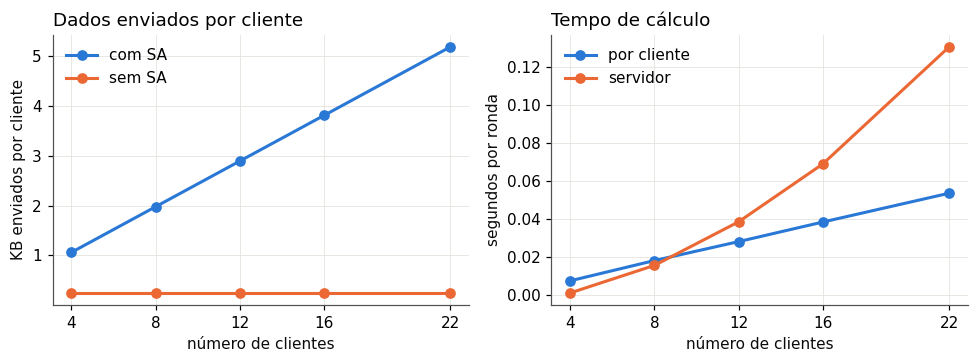

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(e_custo['n'], e_custo['upload_kb'], marker='o', color=COLORS[0], label='com SA')
axes[0].plot(e_custo['n'], e_custo['upload_kb_sem_sa'], marker='o', color=COLORS[1], label='sem SA')
axes[0].set_xlabel('número de clientes'); axes[0].set_ylabel('KB enviados por cliente'); axes[0].legend(frameon=False)
axes[0].set_title('Dados enviados por cliente', loc='left')
axes[1].plot(e_custo['n'], e_custo['tempo_cliente_s'], marker='o', color=COLORS[0], label='por cliente')
axes[1].plot(e_custo['n'], e_custo['tempo_servidor_s'], marker='o', color=COLORS[1], label='servidor')
axes[1].set_xlabel('número de clientes'); axes[1].set_ylabel('segundos por ronda'); axes[1].legend(frameon=False)
axes[1].set_title('Tempo de cálculo', loc='left')
for a in axes: a.set_xticks(e_custo['n'])
save(fig, 'e5_custo_clientes')

### 6.6 Custo: soft labels vs FedAvg (n = 22, t = 12)

In [19]:
payloads = {'soft labels (weighted)': 64, 'soft labels (per_origin)': 128,
            'FedAvg CNN1D (professor Icentia)': 14954, 'FedAvg CNN1D (aluno global)': 20402,
            'FedAvg MobileNetV2 (professor PhysioNet)': 157938}
rows = []; rng = np.random.default_rng(0)
for name, L in payloads.items():
    X = {u: rng.integers(0, 2**16, L).astype(np.uint64) for u in range(1, N+1)}
    tot, rep = sa.secure_sum(X, t=12)
    assert np.array_equal(tot, sum(X.values()) % sa.MOD)
    rows.append(dict(contribuicao=name, valores=L, upload_kb_sem_sa=rep['plain_upload_bytes']/1024,
                     upload_kb_com_sa=rep['upload_bytes_mean']/1024, tempo_total_s=rep['wall_seconds']))
e_fedavg = pd.DataFrame(rows)
e_fedavg['acrescimo_sa_pct'] = 100*(e_fedavg['upload_kb_com_sa']/e_fedavg['upload_kb_sem_sa']-1)
e_fedavg.to_csv(OUT/'e6_softlabels_vs_fedavg.csv', index=False); e_fedavg.round(2)

,contribuicao,valores,upload_kb_sem_sa,upload_kb_com_sa,tempo_total_s,acrescimo_sa_pct
0,soft labels (weighted),64,0.25,5.18,1.32,1970.31
1,soft labels (per_origin),128,0.50,5.43,1.32,985.16
2,FedAvg CNN1D (professor Icentia),14954,58.41,63.34,1.35,8.43
3,FedAvg CNN1D (aluno global),20402,79.70,84.62,1.36,6.18
4,FedAvg MobileNetV2 (professor PhysioNet),157938,616.95,621.87,1.70,0.80


### 6.7 As 3 melhores configurações

In [20]:
# Configurações candidatas; não é um ranking de PR-AUC nem uma prova de segurança.
# Escolher bits no modo de soma única, exigindo MAE < 1e-5 EM CADA ronda,
# sem decisões alteradas; acrescentar quatro bits de margem.
quality=e_bits[e_bits['modo']=='weighted'].groupby('bits').agg(maior_mae=('mae','max'),decisoes=('decisoes_alteradas','sum'))
ok=quality[(quality.maior_mae<1e-5)&(quality.decisoes==0)]
assert len(ok), 'Nenhuma precisão testada satisfaz o critério'
bits_min=int(ok.index.min());bits=min(bits_min+4,sa.max_bits(1))
print('Menor precisão aceitável em todas as rondas:',bits_min,'-> escolhida:',bits)
configs=[('C1 robusta a desistências',8),('C2 equilibrada (maioria)',12),('C3 limiar mais exigente',15)]
rows=[]
for name,t in configs:
    measured=[]
    for r in rounds:
        c,rep,_=sa.sa_consensus(sa.softmax(r['logits']),r['client_ids'],t=t,bits=bits,mode='weighted',planned_weights=r['weights'])
        measured.append(dict(**sa.compare(c,r['consensus']),upload_kb=rep['upload_bytes_mean']/1024,tempo_s=rep['wall_seconds']))
    m=pd.DataFrame(measured)
    rows.append(dict(configuracao=name,modo='weighted',bits=bits,t=t,limiar_shamir_menos_1=t-1,desistencias_toleradas=N-t,
                     sucesso_10pct=p_success(N,t,.1),sucesso_20pct=p_success(N,t,.2),sucesso_30pct=p_success(N,t,.3),
                     mae=m.mae.mean(),erro_max=m.erro_max.max(),decisoes_alteradas=m.decisoes_alteradas.sum(),upload_kb=m.upload_kb.mean(),tempo_s=m.tempo_s.mean()))
top3=pd.DataFrame(rows);top3.to_csv(OUT/'top3_configuracoes.csv',index=False);top3.round(6)


Menor precisão aceitável em todas as rondas: 20 -> escolhida: 24


,configuracao,modo,bits,t,limiar_shamir_menos_1,desistencias_toleradas,sucesso_10pct,sucesso_20pct,sucesso_30pct,mae,erro_max,decisoes_alteradas,upload_kb,tempo_s
0,C1 robusta a desistências,weighted,24,8,7,14,1.000000,0.999999,0.999754,0.0,0.0,0,5.175781,1.266974
1,C2 equilibrada (maioria),weighted,24,12,11,10,0.999998,0.998410,0.961255,0.0,0.0,0,5.175781,1.312194
2,C3 limiar mais exigente,weighted,24,15,14,7,0.999121,0.943855,0.671251,0.0,0.0,0,5.175781,1.344735
